# Microduck in MuJoCo

Training model of the Pollen Robotics Microduck (`microduck_rl`, backlash variant) with the BAM xl330 servo
model and the `velstand` walking policy, run closed loop and animated. Same reference as the Modelica `MicroDuck` library.

Everything is in this notebook; only the data (`velstand.onnx`) and the assets (`model/`: MJCF and meshes) are external.

In [1]:
from pathlib import Path

import imageio
import matplotlib.pyplot as plt
import mujoco
import numpy as np
import onnxruntime as ort
from IPython.display import Video

HERE = Path.cwd()
SCENE = str(HERE / "model" / "scene_backlash.xml")
ONNX = str(HERE / "velstand.onnx")
VIDEO = HERE / "walk.mp4"

JOINTS = [
    "left_hip_yaw", "left_hip_roll", "left_hip_pitch", "left_knee", "left_ankle",
    "neck_pitch", "head_pitch", "head_yaw", "head_roll",
    "right_hip_yaw", "right_hip_roll", "right_hip_pitch", "right_knee", "right_ankle",
]
HEAD = [5, 6, 7, 8]
print("mujoco", mujoco.__version__)

mujoco 3.15.0


## 1. Model

In [2]:
def load(scene):
    model = mujoco.MjModel.from_xml_path(scene)
    data = mujoco.MjData(model)
    qadr = [model.jnt_qposadr[model.joint(j).id] for j in JOINTS]
    dadr = [model.jnt_dofadr[model.joint(j).id] for j in JOINTS]
    return model, data, qadr, dadr


model, data, qadr, dadr = load(SCENE)
print(f"bodies {model.nbody}, joints {model.njnt}, dofs {model.nv}, actuators {model.nu}")
print(f"total mass {model.body_subtreemass[0]:.4f} kg, timestep {model.opt.timestep} s")
print(f"{'joint':<18}{'low [deg]':>10}{'high [deg]':>11}")
for name in JOINTS:
    lo, hi = np.degrees(model.jnt_range[model.joint(name).id])
    print(f"{name:<18}{lo:>10.1f}{hi:>11.1f}")

bodies 16, joints 29, dofs 34, actuators 14
total mass 0.7372 kg, timestep 0.002 s
joint              low [deg] high [deg]
left_hip_yaw           -25.0       30.0
left_hip_roll          -22.0       22.0
left_hip_pitch         -90.0       90.0
left_knee              -90.0       90.0
left_ankle             -90.0       90.0
neck_pitch             -90.0       60.0
head_pitch             -90.0       90.0
head_yaw              -170.0      170.0
head_roll              -25.0       25.0
right_hip_yaw          -30.0       25.0
right_hip_roll         -22.0       22.0
right_hip_pitch        -90.0       90.0
right_knee             -90.0       90.0
right_ankle            -90.0       90.0


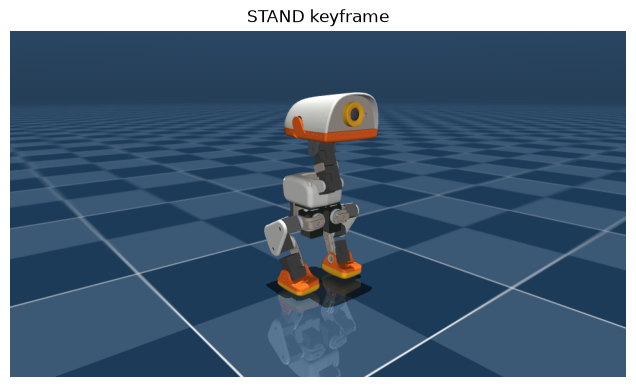

In [3]:
WIDTH, HEIGHT = 960, 540


def make_camera(lookat):
    camera = mujoco.MjvCamera()
    camera.lookat[:] = lookat
    camera.distance, camera.azimuth, camera.elevation = 0.6, 140, -15
    return camera


mujoco.mj_resetDataKeyframe(model, data, model.key("STAND").id)
mujoco.mj_forward(model, data)
model.vis.global_.offwidth, model.vis.global_.offheight = WIDTH, HEIGHT
with mujoco.Renderer(model, HEIGHT, WIDTH) as renderer:
    renderer.update_scene(data, make_camera(data.qpos[:3]))
    image = renderer.render()
plt.figure(figsize=(8, 4.5)); plt.imshow(image); plt.axis("off"); plt.title("STAND keyframe");

## 2. Servo

BAM xl330 voltage model (`m6` parameters) on every joint. The position loop reads the encoder through the 2 deg backlash,
the firmware gain turns the error into a duty cycle on the supply voltage, and the motor torque follows from back-EMF and
winding resistance. Load-dependent friction terms are not modelled.

In [4]:
# bam/params/xl330/m6.json
KT = 0.3459739511711113
RESISTANCE = 2.501880848390462
ARMATURE = 0.001573222677933975
FRICTION_BASE = 0.011919956825702578
FRICTION_VISCOUS = 0.005788445053875673
# bam/dynamixel/actuator.py
SUPPLY = 7.4
ERROR_GAIN = (4096 / (2 * np.pi)) / (256 * 885)
GAIN = 200.0


def backlash_addresses(model):
    """qpos and dof addresses of the passive backlash hinges, empty without backlash."""
    names = [f"passive_{j}_backlash" for j in JOINTS]
    if mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_JOINT, names[0]) < 0:
        return [], []
    return ([model.jnt_qposadr[model.joint(n).id] for n in names],
            [model.jnt_dofadr[model.joint(n).id] for n in names])


def encoder(model, data, qadr, dadr):
    """Joint angles and speeds seen by the servo encoder, through the backlash."""
    bq, bd = backlash_addresses(model)
    q, dq = data.qpos[qadr].copy(), data.qvel[dadr].copy()
    if bq:
        q += data.qpos[bq]
        dq += data.qvel[bd]
    return q, dq


def servo_force(model, data, qadr, dadr, target, gain):
    """Apply the servo torque to the motor-side joints."""
    q, _ = encoder(model, data, qadr, dadr)
    duty = np.clip((target - q) * gain * ERROR_GAIN, -1.0, 1.0)
    dq = data.qvel[dadr]
    data.qfrc_applied[dadr] = KT * SUPPLY * duty / RESISTANCE - KT ** 2 * dq / RESISTANCE


print(f"kt {KT:.4f} N.m/A, R {RESISTANCE:.3f} ohm, armature {ARMATURE:.5f} kg.m2")
print(f"friction {FRICTION_BASE:.4f} N.m, viscous {FRICTION_VISCOUS:.5f} N.m.s, supply {SUPPLY} V, gain {GAIN}")

kt 0.3460 N.m/A, R 2.502 ohm, armature 0.00157 kg.m2
friction 0.0119 N.m, viscous 0.00579 N.m.s, supply 7.4 V, gain 200.0


## 3. Walking policy loop

Robot-software loop: 50 Hz control period, 61 observations (gyro, gravity, joint offsets, joint speeds, previous action, command),
14 targets = home + 0.9 x action, first-order low-pass of 0.7 on the legs and 0.5 on the head. As in training, targets reach
the servos 22.5 ms late and joint speeds are observed one control period late.

In [5]:
PERIOD = 0.02
ACTION_SCALE = 0.9
LEGS_FILTER, HEAD_FILTER = 0.7, 0.5
COMMAND_DELAY = 0.0225  # s, mean of the 3 to 6 steps of 5 ms that training samples every step


def run(scene, policy_path, speed, duration, on_tick=None):
    model, data, qadr, dadr = load(scene)
    model.opt.disableflags |= mujoco.mjtDisableBit.mjDSBL_ACTUATION
    model.dof_armature[dadr] = ARMATURE
    model.dof_damping[dadr] = FRICTION_VISCOUS
    model.dof_frictionloss[dadr] = FRICTION_BASE
    mujoco.mj_setConst(model, data)  # constraint weights (dof_invweight0) from the new armature
    mujoco.mj_resetDataKeyframe(model, data, model.key("STAND").id)
    home = data.qpos[qadr].copy()
    delay_steps = round(COMMAND_DELAY / model.opt.timestep)
    commands = [home.copy()] * (delay_steps + 1)
    observed_speed = np.zeros(14)
    session = ort.InferenceSession(policy_path)
    imu = model.site("imu").id
    command = np.zeros(13)
    command[0] = speed
    last_action = np.zeros(14)
    previous = None
    substeps = round(PERIOD / model.opt.timestep)
    rows = []
    for _ in range(int(duration / PERIOD)):
        mujoco.mj_forward(model, data)
        rot = data.site_xmat[imu].reshape(3, 3)
        omega = np.zeros(6)
        mujoco.mj_objectVelocity(model, data, mujoco.mjtObj.mjOBJ_SITE, imu, omega, 1)  # local frame
        q, dq = encoder(model, data, qadr, dadr)
        obs = np.concatenate([omega[:3], rot.T @ np.array([0, 0, -1.0]), q - home,
                              observed_speed, last_action, command]).astype(np.float32)
        observed_speed = dq
        last_action = session.run(None, {"obs": obs[None]})[0][0].astype(float)
        target = home + ACTION_SCALE * last_action
        if previous is not None:
            for j in range(14):
                alpha = HEAD_FILTER if j in HEAD else LEGS_FILTER
                target[j] = alpha * target[j] + (1 - alpha) * previous[j]
        previous = target.copy()
        for _ in range(substeps):
            commands = commands[1:] + [target]
            servo_force(model, data, qadr, dadr, commands[0], GAIN)
            mujoco.mj_step(model, data)
        if on_tick:
            on_tick(data)
        w, x, y, z = data.qpos[3:7]
        rows.append({"t": float(data.time), "pos": data.qpos[:3].tolist(),
                     "pitch": float(np.arcsin(np.clip(2 * (w * y - z * x), -1, 1))),
                     "q": encoder(model, data, qadr, dadr)[0].tolist()})
    return rows

## 4. Run and animate

In [6]:
SPEED, DURATION = 0.3, 6.0

render_model = mujoco.MjModel.from_xml_path(SCENE)
render_model.vis.global_.offwidth, render_model.vis.global_.offheight = WIDTH, HEIGHT
renderer = mujoco.Renderer(render_model, HEIGHT, WIDTH)
camera = make_camera([0, 0, 0.1])
writer = imageio.get_writer(str(VIDEO), fps=round(1 / PERIOD), macro_block_size=1)


def grab(d):
    camera.lookat[:] = d.qpos[:3]
    renderer.update_scene(d, camera)
    writer.append_data(renderer.render())


series = run(SCENE, ONNX, SPEED, DURATION, on_tick=grab)
writer.close(); renderer.close()
print(f"{len(series)} frames, final x {series[-1]['pos'][0]:.3f} m")

300 frames, final x 0.799 m


In [7]:
Video(str(VIDEO), embed=True, width=720)

## 5. Results

mean speed over last 4 s: 0.132 m/s (command 0.3)


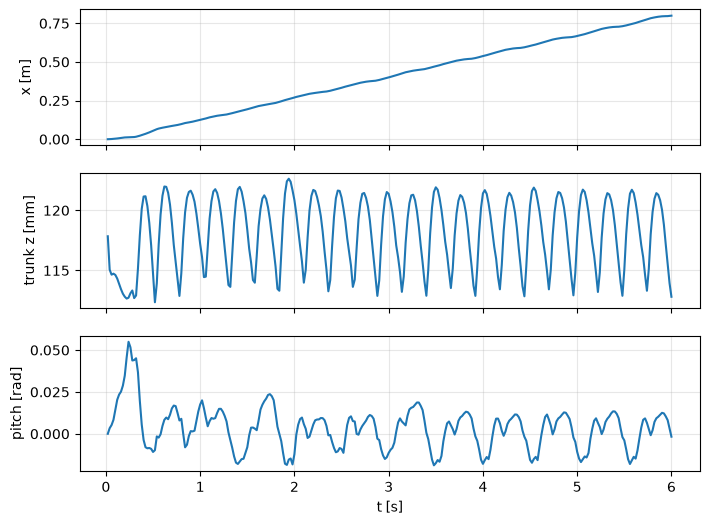

In [8]:
t = np.array([r["t"] for r in series])
x = np.array([r["pos"][0] for r in series])
z = np.array([r["pos"][2] for r in series])
pitch = np.array([r["pitch"] for r in series])
fig, ax = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
ax[0].plot(t, x); ax[0].set_ylabel("x [m]")
ax[1].plot(t, 1000 * z); ax[1].set_ylabel("trunk z [mm]")
ax[2].plot(t, pitch); ax[2].set_ylabel("pitch [rad]"); ax[2].set_xlabel("t [s]")
for a in ax:
    a.grid(alpha=0.3)
tail = t > t[-1] - 4
print(f"mean speed over last 4 s: {(x[-1] - x[tail][0]) / 4:.3f} m/s (command {SPEED})")